# Forecast validation

Evaluate fixed and expanding-window ARX(2) forecasts with oil lag 2 and FX lag 4 on 2022Q1–2024Q2. Preserve the fixed pre-2022 model and compare its validation accuracy with adaptive refitting.

Run from `notebooks/`. Inputs: the split CSVs from Notebook 3 and the candidate manifest from Notebook 4. Final testing, benchmarks and scenarios are handled separately.

## Imports and configuration

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

TRAIN_DATA_PATH = Path("../data/processed/train.csv")
EVALUATION_DATA_PATH = Path("../data/processed/test.csv")
EXPECTED_COLUMNS = ["quarter", "npl", "brent", "usdkzt"]
VALUE_COLUMNS = EXPECTED_COLUMNS[1:]
QUARTER_FREQUENCY = "Q-DEC"
CANDIDATE_MANIFEST_PATH = Path("../reports/diagnostics/04_arx_candidate_manifest.json")
TARGET_COLUMN = "npl_change_pp"
CHANGE_COLUMNS = [TARGET_COLUMN, "brent_log_change_pct", "usdkzt_log_change_pct"]
NPL_LAGS = [1, 2]
MAX_FEATURE_LAG = 4
MAIN_MODEL_NAME = "ARX2_oil2_fx4"
DIAGNOSTIC_DIRECTORY = Path("../reports/diagnostics")
VALIDATION_PROTOCOL_PATH = DIAGNOSTIC_DIRECTORY / "05_validation_protocol.json"

TRAIN_START = pd.Period("2010Q1", freq=QUARTER_FREQUENCY)
TRAIN_END = pd.Period("2021Q4", freq=QUARTER_FREQUENCY)
VALIDATION_START = pd.Period("2022Q1", freq=QUARTER_FREQUENCY)
VALIDATION_END = pd.Period("2024Q2", freq=QUARTER_FREQUENCY)
TEST_START = pd.Period("2024Q3", freq=QUARTER_FREQUENCY)
TEST_END = pd.Period("2026Q2", freq=QUARTER_FREQUENCY)

assert TRAIN_DATA_PATH.exists(), "Run Notebook 3 to save the training dataset."
assert EVALUATION_DATA_PATH.exists(), "Run Notebook 3 to save the evaluation pool."
assert CANDIDATE_MANIFEST_PATH.exists(), "Run Notebook 4 to save the ARX shortlist."
ADAPTIVE_MODEL_NAME = f"{MAIN_MODEL_NAME}_expanding"
ADAPTIVE_VALIDATION_PATH = DIAGNOSTIC_DIRECTORY / "05_adaptive_validation.json"

## Data import and checks

Load the original quarterly levels saved by Notebook 3. `train.csv` contains 48 pre-2022 quarters; `test.csv` contains the full 18-quarter evaluation pool, not only the final test period. Neither file is modified.

In [2]:
def load_quarterly_data(data_path):
    # validate each saved snapshot before using its quarter index
    data = pd.read_csv(data_path)
    assert list(data.columns) == EXPECTED_COLUMNS
    assert not data.isna().any().any()
    assert data["quarter"].str.fullmatch(r"\d{4}Q[1-4]").all()
    assert all(pd.api.types.is_numeric_dtype(data[column]) for column in VALUE_COLUMNS)
    assert np.isfinite(data[VALUE_COLUMNS].to_numpy()).all()
    assert data["npl"].between(0, 100).all()
    assert (data[["brent", "usdkzt"]] > 0).all().all()

    quarter_index = pd.PeriodIndex(data["quarter"], freq=QUARTER_FREQUENCY)
    assert quarter_index.is_unique
    assert quarter_index.is_monotonic_increasing
    assert quarter_index.equals(
        pd.period_range(quarter_index.min(), quarter_index.max(), freq=QUARTER_FREQUENCY)
    )

    data = data.drop(columns="quarter")
    data.index = quarter_index.rename("quarter")
    return data


train_data = load_quarterly_data(TRAIN_DATA_PATH)
evaluation_data = load_quarterly_data(EVALUATION_DATA_PATH)

# check the original 48/18 boundary before dividing the evaluation pool
assert train_data.index.equals(
    pd.period_range(TRAIN_START, TRAIN_END, freq=QUARTER_FREQUENCY)
)
assert evaluation_data.index.equals(
    pd.period_range(VALIDATION_START, TEST_END, freq=QUARTER_FREQUENCY)
)
assert len(train_data) == 48
assert len(evaluation_data) == 18

display(train_data.head())
train_data.info()

<class 'pandas.core.frame.DataFrame'>
PeriodIndex: 48 entries, 2010Q1 to 2021Q4
Freq: Q-DEC
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   npl     48 non-null     float64
 1   brent   48 non-null     float64
 2   usdkzt  48 non-null     float64
dtypes: float64(3)
memory usage: 2.5 KB


,npl,brent,usdkzt
quarter,,,
2010Q1,24.9600,76.6700,147.7000
2010Q2,25.2500,78.8500,146.8100
2010Q3,25.8300,76.6800,147.4100
2010Q4,23.7500,87.0300,147.4900
2011Q1,25.2700,105.3700,146.4200


## Evaluation periods

Use 2010Q1–2021Q4 for initial fitting, 2022Q1–2024Q2 for validation and 2024Q3–2026Q2 for final testing. Compare fixed and adaptive update policies without another lag search. Test outcomes remain unscored.

In [3]:
# split the held-out pool chronologically without transforming the series
validation_data = evaluation_data.loc[VALIDATION_START:VALIDATION_END].copy()
test_data = evaluation_data.loc[TEST_START:TEST_END].copy()

assert len(validation_data) == 10
assert len(test_data) == 8
assert validation_data.index.equals(
    pd.period_range(VALIDATION_START, VALIDATION_END, freq=QUARTER_FREQUENCY)
)
assert test_data.index.equals(
    pd.period_range(TEST_START, TEST_END, freq=QUARTER_FREQUENCY)
)

# verify disjoint, consecutive periods and unchanged observations
assert train_data.index.intersection(validation_data.index).empty
assert train_data.index.intersection(test_data.index).empty
assert validation_data.index.intersection(test_data.index).empty
assert train_data.index.max() + 1 == validation_data.index.min()
assert validation_data.index.max() + 1 == test_data.index.min()

pd.testing.assert_frame_equal(
    pd.concat([validation_data, test_data]),
    evaluation_data,
)

full_data = pd.concat([train_data, evaluation_data])
split_data = pd.concat([train_data, validation_data, test_data])

assert full_data.index.equals(
    pd.period_range(TRAIN_START, TEST_END, freq=QUARTER_FREQUENCY)
)
assert len(full_data) == 66
pd.testing.assert_frame_equal(split_data, full_data)

### Period summary

Counts refer to original observations, before differencing and lag construction.

In [4]:
evaluation_periods = pd.DataFrame(
    [
        {
            "sample": sample_name,
            "start": str(sample_data.index.min()),
            "end": str(sample_data.index.max()),
            "quarters": len(sample_data),
            "purpose": purpose,
        }
        for sample_name, sample_data, purpose in [
            ("Training", train_data, "Fit model parameters"),
            ("Validation", validation_data, "Check ARX forecasts and procedure"),
            ("Final test", test_data, "Evaluate the fixed specification"),
        ]
    ]
).set_index("sample")

assert evaluation_periods["quarters"].tolist() == [48, 10, 8]
assert evaluation_periods["quarters"].sum() == 66

display(evaluation_periods)

,start,end,quarters,purpose
sample,,,,
Training,2010Q1,2021Q4,48,Fit model parameters
Validation,2022Q1,2024Q2,10,Check ARX forecasts and procedure
Final test,2024Q3,2026Q2,8,Evaluate the fixed specification


## Transformations and lagged inputs

Reuse NPL differences in percentage points and oil/FX log differences ×100. Calculate backward-looking changes and lags before selecting target periods to preserve boundary history. No scaling or additional rounding is applied.

Forecasts assume previous-quarter observations are available. Publication delays and revisions are not simulated. Test inputs are prepared but not displayed or scored.

In [5]:
# calculate backward-looking changes without scaling or rounding
changes = pd.DataFrame({
    TARGET_COLUMN: full_data["npl"].diff(),
    "brent_log_change_pct": np.log(full_data["brent"]).diff() * 100,
    "usdkzt_log_change_pct": np.log(full_data["usdkzt"]).diff() * 100,
}, index=full_data.index)

assert changes.iloc[0].isna().all()
assert changes.iloc[1:].notna().all().all()
assert np.isfinite(changes.iloc[1:].to_numpy()).all()

# verify that extending the chronology leaves training transformations unchanged
training_changes = pd.DataFrame({
    TARGET_COLUMN: train_data["npl"].diff(),
    "brent_log_change_pct": np.log(train_data["brent"]).diff() * 100,
    "usdkzt_log_change_pct": np.log(train_data["usdkzt"]).diff() * 100,
}, index=train_data.index)
pd.testing.assert_frame_equal(changes.loc[train_data.index], training_changes)

lagged_features = pd.DataFrame(index=full_data.index)
for column in CHANGE_COLUMNS:
    for lag in range(1, MAX_FEATURE_LAG + 1):
        feature = f"{column}_lag_{lag}"
        lagged_features[feature] = changes[column].shift(lag)
        assert lagged_features[feature].iloc[:lag + 1].isna().all()
        assert lagged_features[feature].iloc[lag + 1:].notna().all()

assert lagged_features.shape == (66, 12)
assert TARGET_COLUMN not in lagged_features.columns
display(training_changes.head())

,npl_change_pp,brent_log_change_pct,usdkzt_log_change_pct
quarter,,,
2010Q1,NaN,NaN,NaN
2010Q2,0.2900,2.8037,-0.6044
2010Q3,0.5800,-2.7906,0.4079
2010Q4,-2.0800,12.6612,0.0543
2011Q1,1.5200,19.1225,-0.7281


### Sample alignment

The common lagged training sample contains 43 rows. Preserve all 10 validation and 8 test target quarters by retaining preceding observations; check every predictor against its earlier source quarter.

In [6]:
# retain the common 43-row training sample used for arx selection
training_model_data = pd.concat(
    [changes[[TARGET_COLUMN]], lagged_features], axis=1
).loc[train_data.index].dropna().copy()

X_train = training_model_data[lagged_features.columns].copy()
y_train = training_model_data[TARGET_COLUMN].copy()
X_validation = lagged_features.loc[validation_data.index].copy()
X_test = lagged_features.loc[test_data.index].copy()

assert X_train.index.equals(train_data.index[MAX_FEATURE_LAG + 1:])
assert X_train.index.equals(y_train.index)
assert len(X_train) == 43
assert X_train.index.max() == TRAIN_END
assert X_validation.index.equals(validation_data.index)
assert X_test.index.equals(test_data.index)
assert len(X_validation) == 10 and len(X_test) == 8

# verify every predictor against its earlier source quarter in all periods
complete_features = pd.concat([X_train, X_validation, X_test])
for column in CHANGE_COLUMNS:
    for lag in range(1, MAX_FEATURE_LAG + 1):
        source_quarters = complete_features.index - lag
        expected_values = changes.loc[source_quarters, column].set_axis(
            complete_features.index
        )
        pd.testing.assert_series_equal(
            complete_features[f"{column}_lag_{lag}"],
            expected_values,
            check_names=False,
            check_exact=True,
        )
        assert (source_quarters <= complete_features.index - 1).all()

assert np.isfinite(complete_features.to_numpy()).all()
assert np.isfinite(y_train.to_numpy()).all()

# store the last observed level separately from current-quarter outcomes
forecast_context = pd.DataFrame({
    "forecast_origin_quarter": full_data.index - 1,
    "latest_observed_npl": full_data["npl"].shift(1),
}, index=full_data.index)
assert forecast_context.loc[complete_features.index].notna().all().all()
assert (
    forecast_context.loc[complete_features.index, "forecast_origin_quarter"]
    == complete_features.index - 1
).all()
np.testing.assert_allclose(
    forecast_context.loc[y_train.index, "latest_observed_npl"] + y_train,
    train_data.loc[y_train.index, "npl"],
    rtol=0,
    atol=1e-12,
)

input_summary = pd.DataFrame([
    {
        "sample": sample_name,
        "first_target": str(sample_inputs.index.min()),
        "last_target": str(sample_inputs.index.max()),
        "complete_rows": len(sample_inputs),
        "candidate_predictors": sample_inputs.shape[1],
    }
    for sample_name, sample_inputs in [
        ("Training", X_train),
        ("Validation", X_validation),
        ("Final test", X_test),
    ]
]).set_index("sample")

display(input_summary)
display(
    forecast_context.loc[X_validation.index].join(X_validation).head()
)

,first_target,last_target,complete_rows,candidate_predictors
sample,,,,
Training,2011Q2,2021Q4,43,12
Validation,2022Q1,2024Q2,10,12
Final test,2024Q3,2026Q2,8,12


,forecast_origin_quarter,latest_observed_npl,npl_change_pp_lag_1,npl_change_pp_lag_2,npl_change_pp_lag_3,npl_change_pp_lag_4,brent_log_change_pct_lag_1,brent_log_change_pct_lag_2,brent_log_change_pct_lag_3,brent_log_change_pct_lag_4,usdkzt_log_change_pct_lag_1,usdkzt_log_change_pct_lag_2,usdkzt_log_change_pct_lag_3,usdkzt_log_change_pct_lag_4
quarter,,,,,,,,,,,,,,
2022Q1,2021Q4,3.3100,-0.9800,-0.4800,-2.3300,0.2500,8.5771,5.7745,12.3131,29.8813,0.9515,-0.6182,2.0424,-1.5415
2022Q2,2022Q1,3.5700,0.2600,-0.9800,-0.4800,-2.3300,19.9588,8.5771,5.7745,12.3131,5.7242,0.9515,-0.6182,2.0424
2022Q3,2022Q2,3.6100,0.0400,0.2600,-0.9800,-0.4800,13.9173,19.9588,8.5771,5.7745,-2.8099,5.7242,0.9515,-0.6182
2022Q4,2022Q3,3.6000,-0.0100,0.0400,0.2600,-0.9800,-13.5178,13.9173,19.9588,8.5771,7.1758,-2.8099,5.7242,0.9515
2023Q1,2022Q4,3.3600,-0.2400,-0.0100,0.0400,0.2600,-9.7746,-13.5178,13.9173,19.9588,-1.6008,7.1758,-2.8099,5.7242


## ARX specification

Carry forward `ARX2_oil2_fx4`: NPL-change lags 1–2, oil-change lag 2 and FX-change lag 4. This specification led on training AICc in Notebook 4. Verify its definition and training-file fingerprint against the saved manifest.

In [7]:
candidate_manifest = json.loads(
    CANDIDATE_MANIFEST_PATH.read_text(encoding="utf-8")
)
assert candidate_manifest["training_input_sha256"] == hashlib.sha256(
    TRAIN_DATA_PATH.read_bytes()
).hexdigest()
assert candidate_manifest["training_end"] == str(TRAIN_END)
assert candidate_manifest["target"] == TARGET_COLUMN
assert candidate_manifest["npl_lags"] == NPL_LAGS
assert candidate_manifest["model_observations"] == len(y_train)
assert candidate_manifest["model_sample_start"] == str(y_train.index.min())
assert candidate_manifest["model_sample_end"] == str(y_train.index.max())
assert MAIN_MODEL_NAME in candidate_manifest["shortlisted_models"]

# retain only the selected model from the historical search
selected_models = [MAIN_MODEL_NAME]
selected_specification = next(
    item for item in candidate_manifest["candidate_specifications"]
    if item["model"] == MAIN_MODEL_NAME
)
arx_specifications = [selected_specification]

assert selected_specification["oil_lag"] == 2
assert selected_specification["fx_lag"] == 4
assert selected_specification["predictors"] == [
    f"{TARGET_COLUMN}_lag_1",
    f"{TARGET_COLUMN}_lag_2",
    "brent_log_change_pct_lag_2",
    "usdkzt_log_change_pct_lag_4",
]
assert set(selected_specification["predictors"]).issubset(X_train.columns)

display(pd.DataFrame([{
    "model": MAIN_MODEL_NAME,
    "oil_lag": selected_specification["oil_lag"],
    "fx_lag": selected_specification["fx_lag"],
}]).set_index("model"))

,oil_lag,fx_lag
model,,
ARX2_oil2_fx4,2,4


### Training fit

Refit the selected OLS equation on the same 43 pre-2022 target quarters as Notebook 4. Retain its coefficients unchanged for the fixed-model forecasts.

In [8]:
fitted_models = {}
model_predictors = {}
fit_rows = []

saved_fit_comparison = pd.DataFrame(
    candidate_manifest["fit_comparison"]
).set_index("model")

# fit only training targets and reproduce the selected earlier fit
for specification in arx_specifications:
    model_name = specification["model"]
    predictors = specification["predictors"]
    design_matrix = sm.add_constant(X_train[predictors], has_constant="add")
    assert design_matrix.index.equals(y_train.index)
    assert design_matrix.index.max() <= TRAIN_END
    assert design_matrix.shape == (43, 5)
    assert np.linalg.matrix_rank(design_matrix.to_numpy()) == 5

    result = sm.OLS(y_train, design_matrix, missing="raise").fit()
    assert int(result.nobs) == 43
    assert np.isfinite(result.params.to_numpy()).all()

    parameter_count = len(result.params) + 1
    reproduced_aic = -2 * result.llf + 2 * parameter_count
    np.testing.assert_allclose(
        reproduced_aic,
        saved_fit_comparison.loc[model_name, "aic"],
        rtol=0,
        atol=1e-8,
    )
    fitted_models[model_name] = result
    model_predictors[model_name] = predictors
    fit_rows.append({
        "model": model_name,
        "estimator": "OLS ARX",
        "fit_start": str(y_train.index.min()),
        "fit_end": str(y_train.index.max()),
        "fit_observations": int(result.nobs),
        "estimated_parameters_including_variance": parameter_count,
    })

arx_coefficients = pd.DataFrame([
    {
        "model": name,
        "parameter": parameter,
        "estimate": value,
    }
    for name in selected_models
    for parameter, value in fitted_models[name].params.items()
]).set_index(["model", "parameter"])
assert np.isfinite(arx_coefficients.to_numpy()).all()
display(arx_coefficients)

# confirm that only the selected arx model is fitted
assert list(fitted_models) == [MAIN_MODEL_NAME]
fit_summary = pd.DataFrame(fit_rows).set_index("model")
assert fit_summary["fit_observations"].eq(43).all()
assert fit_summary["fit_end"].eq(str(TRAIN_END)).all()
display(fit_summary)

estimate
model         parameter                            
ARX2_oil2_fx4 const                         -0.1869
              npl_change_pp_lag_1           -0.0367
              npl_change_pp_lag_2            0.3413
              brent_log_change_pct_lag_2     0.0569
              usdkzt_log_change_pct_lag_4   -0.0647

,estimator,fit_start,fit_end,fit_observations,estimated_parameters_including_variance
model,,,,,
ARX2_oil2_fx4,OLS ARX,2011Q2,2021Q4,43,6


## Fixed-model validation

Forecast each validation quarter from observations through $t-1$, keeping coefficients fixed. Update lagged inputs with actual previous-quarter observations and reconstruct the NPL level:

$\widehat{NPL}_t=NPL_{t-1}+\widehat{\Delta NPL}_t$.

These are rolling one-quarter-ahead forecasts, not a ten-quarter forecast from one origin. Join current-quarter actuals after prediction. No clipping or bias correction is applied.

In [9]:
def make_arx_forecast_inputs(history, target_quarter, predictors):
    # rebuild predictors using only observations available at the origin
    origin_quarter = target_quarter - 1
    assert history.index.is_unique and history.index.is_monotonic_increasing
    assert history.index.max() == origin_quarter
    assert (history.index <= origin_quarter).all()

    history_changes = pd.DataFrame({
        TARGET_COLUMN: history["npl"].diff(),
        "brent_log_change_pct": np.log(history["brent"]).diff() * 100,
        "usdkzt_log_change_pct": np.log(history["usdkzt"]).diff() * 100,
    }, index=history.index)

    predictor_values = {}
    for feature in predictors:
        source_column, lag_text = feature.rsplit("_lag_", 1)
        lag = int(lag_text)
        source_quarter = target_quarter - lag
        assert lag >= 1 and source_quarter <= origin_quarter
        predictor_values[feature] = history_changes.loc[source_quarter, source_column]

    inputs = pd.DataFrame(
        [predictor_values],
        index=pd.PeriodIndex([target_quarter], freq=QUARTER_FREQUENCY),
    ).rename_axis("quarter")
    assert list(inputs.columns) == predictors
    assert np.isfinite(inputs.to_numpy()).all()
    return sm.add_constant(inputs, has_constant="add")


arx_result = fitted_models[MAIN_MODEL_NAME]
frozen_parameters = arx_result.params.copy()
selected_predictors = model_predictors[MAIN_MODEL_NAME]
validation_history = pd.concat([train_data, validation_data])
forecast_rows = []

# generate forecasts without accessing current-quarter npl outcomes
for target_quarter in validation_data.index:
    origin_quarter = target_quarter - 1
    observed_history = validation_history.loc[:origin_quarter].copy()
    forecast_inputs = make_arx_forecast_inputs(
        observed_history, target_quarter, selected_predictors
    )
    assert list(forecast_inputs.columns) == arx_result.model.exog_names
    pd.testing.assert_frame_equal(
        forecast_inputs,
        sm.add_constant(
            X_validation.loc[[target_quarter], selected_predictors],
            has_constant="add",
        ),
        check_exact=True,
    )

    predicted_change = float(arx_result.predict(forecast_inputs).iloc[0])
    latest_npl = float(observed_history["npl"].iloc[-1])
    forecast_rows.append({
        "quarter": target_quarter,
        "forecast_origin_quarter": origin_quarter,
        "latest_observed_npl": latest_npl,
        "predicted_change_pp": predicted_change,
        "predicted_npl": latest_npl + predicted_change,
    })

validation_forecasts = pd.DataFrame(forecast_rows).set_index("quarter")
assert validation_forecasts.index.equals(validation_data.index)
assert len(validation_forecasts) == 10
assert validation_forecasts.index.intersection(test_data.index).empty
assert (
    validation_forecasts["forecast_origin_quarter"]
    == validation_forecasts.index - 1
).all()
assert np.isfinite(
    validation_forecasts.select_dtypes(include=np.number).to_numpy()
).all()
pd.testing.assert_series_equal(
    validation_forecasts["latest_observed_npl"],
    forecast_context.loc[validation_data.index, "latest_observed_npl"],
    check_exact=True,
)
pd.testing.assert_series_equal(arx_result.params, frozen_parameters, check_exact=True)

# independently check prediction arithmetic with the fixed coefficient vector
validation_design = sm.add_constant(
    X_validation[selected_predictors], has_constant="add"
)
np.testing.assert_allclose(
    validation_forecasts["predicted_change_pp"],
    validation_design.to_numpy() @ frozen_parameters.to_numpy(),
    rtol=0,
    atol=1e-12,
)
display(validation_forecasts)

,forecast_origin_quarter,latest_observed_npl,predicted_change_pp,predicted_npl
quarter,,,,
2022Q1,2021Q4,3.3100,0.1136,3.4236
2022Q2,2022Q1,3.5700,-0.1751,3.3949
2022Q3,2022Q2,3.6100,1.0761,4.6861
2022Q4,2022Q3,3.6000,0.5575,4.1575
2023Q1,2022Q4,3.3600,-1.3213,2.0387
2023Q2,2023Q1,3.4400,-0.6460,2.7940
2023Q3,2023Q2,3.2900,-1.0447,2.2453
2023Q4,2023Q3,3.2700,-0.4339,2.8361
2024Q1,2023Q4,2.8900,0.5495,3.4395


### Forecast accuracy

Define error as actual minus forecast: positive means underprediction, negative means overprediction. MAE, RMSE and mean error are measured in NPL percentage points.

In [10]:
# use validation outcomes for scoring only, not parameter estimation
validation_results = validation_forecasts.join(
    validation_data["npl"].rename("actual_npl"),
    how="left",
    validate="one_to_one",
)
validation_results["error_pp"] = (
    validation_results["actual_npl"] - validation_results["predicted_npl"]
)
validation_results["absolute_error_pp"] = validation_results["error_pp"].abs()

assert validation_results.index.equals(validation_data.index)
assert not validation_results.isna().any().any()
assert np.isfinite(
    validation_results.select_dtypes(include=np.number).to_numpy()
).all()
np.testing.assert_allclose(
    validation_results["predicted_npl"],
    validation_results["latest_observed_npl"] + validation_results["predicted_change_pp"],
    rtol=0,
    atol=1e-12,
)

validation_errors = validation_results["error_pp"]
validation_metrics = pd.DataFrame([{
    "model": MAIN_MODEL_NAME,
    "observations": len(validation_results),
    "mae_pp": validation_errors.abs().mean(),
    "rmse_pp": np.sqrt(np.mean(validation_errors.to_numpy() ** 2)),
    "mean_error_pp": validation_errors.mean(),
    "underpredicted_quarters": int(validation_errors.gt(0).sum()),
    "overpredicted_quarters": int(validation_errors.lt(0).sum()),
    "exact_quarters": int(validation_errors.eq(0).sum()),
}]).set_index("model")

assert validation_metrics.loc[MAIN_MODEL_NAME, "observations"] == 10
assert np.isfinite(validation_metrics.to_numpy()).all()
assert validation_metrics.loc[MAIN_MODEL_NAME, "rmse_pp"] >= (
    validation_metrics.loc[MAIN_MODEL_NAME, "mae_pp"] - 1e-12
)
assert validation_metrics[[
    "underpredicted_quarters", "overpredicted_quarters", "exact_quarters"
]].sum(axis=1).iloc[0] == len(validation_results)

display(validation_results)
display(validation_metrics)

,forecast_origin_quarter,latest_observed_npl,predicted_change_pp,predicted_npl,actual_npl,error_pp,absolute_error_pp
quarter,,,,,,,
2022Q1,2021Q4,3.3100,0.1136,3.4236,3.5700,0.1464,0.1464
2022Q2,2022Q1,3.5700,-0.1751,3.3949,3.6100,0.2151,0.2151
2022Q3,2022Q2,3.6100,1.0761,4.6861,3.6000,-1.0861,1.0861
2022Q4,2022Q3,3.6000,0.5575,4.1575,3.3600,-0.7975,0.7975
2023Q1,2022Q4,3.3600,-1.3213,2.0387,3.4400,1.4013,1.4013
2023Q2,2023Q1,3.4400,-0.6460,2.7940,3.2900,0.4960,0.4960
2023Q3,2023Q2,3.2900,-1.0447,2.2453,3.2700,1.0247,1.0247
2023Q4,2023Q3,3.2700,-0.4339,2.8361,2.8900,0.0539,0.0539
2024Q1,2023Q4,2.8900,0.5495,3.4395,3.0700,-0.3695,0.3695


,observations,mae_pp,rmse_pp,mean_error_pp,underpredicted_quarters,overpredicted_quarters,exact_quarters
model,,,,,,,
ARX2_oil2_fx4,10,0.6054,0.7414,0.1548,7,3,0


### Forecast plots

Display actual and predicted NPL levels, followed by signed quarterly errors. All charts remain inline.

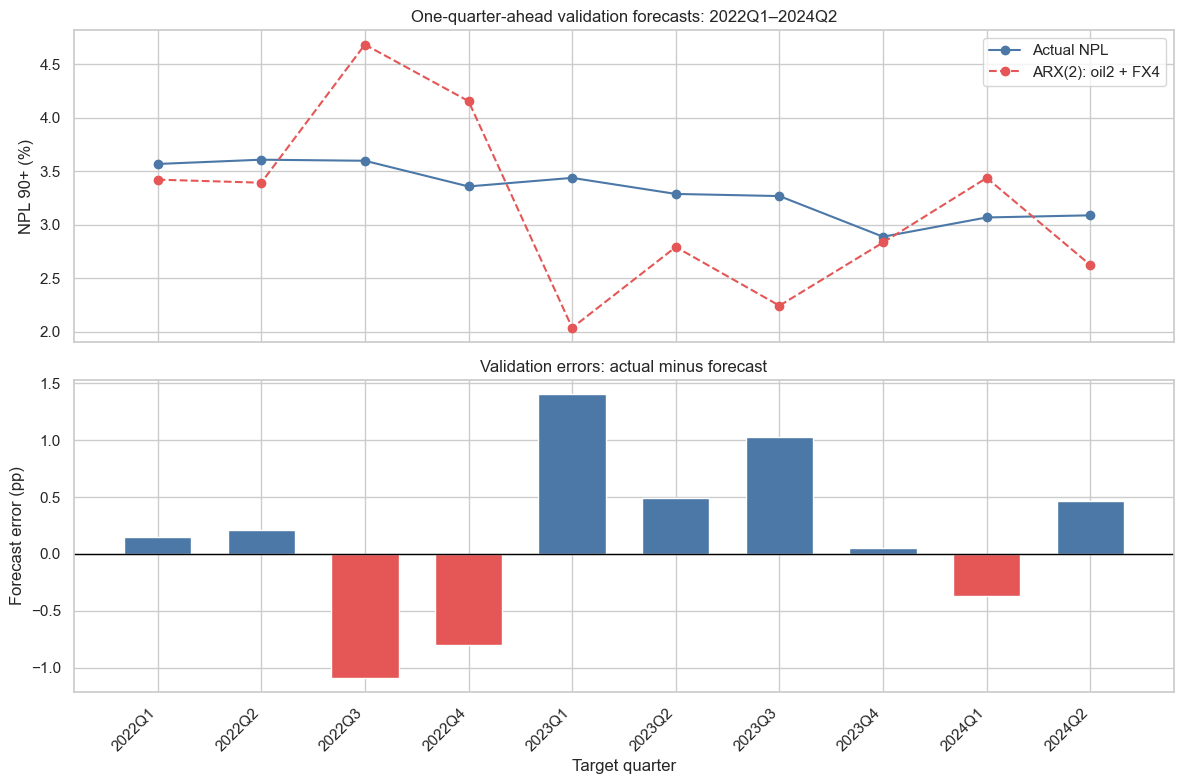

In [11]:
quarter_positions = np.arange(len(validation_results))
figure, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# compare forecasts and observations in their original units
axes[0].plot(
    quarter_positions,
    validation_results["actual_npl"],
    color="#4C78A8",
    marker="o",
    label="Actual NPL",
)
axes[0].plot(
    quarter_positions,
    validation_results["predicted_npl"],
    color="#E45756",
    marker="o",
    linestyle="--",
    label="ARX(2): oil2 + FX4",
)
axes[0].set(
    title="One-quarter-ahead validation forecasts: 2022Q1–2024Q2",
    ylabel="NPL 90+ (%)",
)
axes[0].legend()

# show positive underprediction and negative overprediction errors
axes[1].bar(
    quarter_positions,
    validation_results["error_pp"],
    color=np.where(validation_results["error_pp"] >= 0, "#4C78A8", "#E45756"),
    width=0.65,
)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(
    title="Validation errors: actual minus forecast",
    xlabel="Target quarter",
    ylabel="Forecast error (pp)",
)
axes[1].set_xticks(quarter_positions)
axes[1].set_xticklabels(
    validation_results.index.astype(str),
    rotation=45,
    ha="right",
)

figure.tight_layout()
plt.show()
plt.close(figure)

### Validation review

MAE is 0.605 pp and RMSE 0.741 pp. Mean error is +0.155 pp, with seven underpredictions and three overpredictions. Forecasts vary more than actual NPL; the largest absolute error occurs in 2023Q1.

Retain the fixed specification without recalibration. Ten observations provide limited evidence; benchmark performance has not yet been assessed.

In [12]:
# inspect the largest errors without removing any quarter
largest_validation_errors = validation_results.nlargest(
    3, "absolute_error_pp"
)[["actual_npl", "predicted_npl", "error_pp", "absolute_error_pp"]]

validation_range_summary = pd.DataFrame({
    "minimum": validation_results[["actual_npl", "predicted_npl"]].min(),
    "maximum": validation_results[["actual_npl", "predicted_npl"]].max(),
})
validation_range_summary["range_pp"] = (
    validation_range_summary["maximum"] - validation_range_summary["minimum"]
)

assert len(largest_validation_errors) == 3
assert len(validation_results) == 10
assert arx_result.model.data.row_labels.max() == TRAIN_END
assert list(fitted_models) == [MAIN_MODEL_NAME]
pd.testing.assert_series_equal(arx_result.params, frozen_parameters, check_exact=True)

display(largest_validation_errors)
display(validation_range_summary)

,actual_npl,predicted_npl,error_pp,absolute_error_pp
quarter,,,,
2023Q1,3.4400,2.0387,1.4013,1.4013
2022Q3,3.6000,4.6861,-1.0861,1.0861
2023Q3,3.2700,2.2453,1.0247,1.0247


,minimum,maximum,range_pp
actual_npl,2.8900,3.6100,0.7200
predicted_npl,2.0387,4.6861,2.6474


### Save the fixed-model results

Preserve the specification, coefficients, forecasts and evaluation rules in `reports/diagnostics/05_validation_protocol.json`. Identical reruns reproduce the artifact; changed results require review before replacement.

In [13]:
# serialize validation-only results without rounding numerical values
validation_export = validation_results.reset_index().copy()
for column in ["quarter", "forecast_origin_quarter"]:
    validation_export[column] = validation_export[column].astype(str)

validation_records = [
    {
        key: value.item() if isinstance(value, np.generic) else value
        for key, value in record.items()
    }
    for record in validation_export.to_dict(orient="records")
]
metric_record = {
    key: value.item() if isinstance(value, np.generic) else value
    for key, value in validation_metrics.reset_index().to_dict(orient="records")[0].items()
}

validation_protocol = {
    "status": "procedure_fixed_final_testing_pending_authorization",
    "model": MAIN_MODEL_NAME,
    "predictors": selected_predictors,
    "target": TARGET_COLUMN,
    "transformations": candidate_manifest["transformations"],
    "training_input_sha256": hashlib.sha256(TRAIN_DATA_PATH.read_bytes()).hexdigest(),
    "training_fit": {
        "start": str(y_train.index.min()),
        "end": str(y_train.index.max()),
        "observations": len(y_train),
        "coefficients": {
            name: float(value) for name, value in frozen_parameters.items()
        },
    },
    "evaluation_periods": {
        "validation": {"start": str(VALIDATION_START), "end": str(VALIDATION_END), "quarters": 10},
        "final_test": {"start": str(TEST_START), "end": str(TEST_END), "quarters": 8},
    },
    "forecast_rules": {
        "horizon_quarters": 1,
        "origin": "target quarter minus one",
        "parameters": "fixed; fitted on pre-2022 data only",
        "history_update": "use actual previous-quarter observations, not previous predictions",
        "availability_assumption": "all previous-quarter data observed; no release-vintage simulation",
        "level_reconstruction": "last observed NPL plus predicted NPL change",
        "error_definition": "actual NPL minus predicted NPL",
        "metric_units": "NPL percentage points",
        "bias_correction": False,
        "prediction_clipping": False,
        "excluded_validation_quarters": [],
    },
    "validation_metrics": metric_record,
    "validation_forecasts": validation_records,
    "final_testing_performed": False,
    "benchmarks_evaluated": [],
    "stress_scenario_performed": False,
    "final_interpretation_written": False,
}

assert len(validation_protocol["validation_forecasts"]) == 10
assert all(
    VALIDATION_START <= pd.Period(row["quarter"], freq=QUARTER_FREQUENCY) <= VALIDATION_END
    for row in validation_protocol["validation_forecasts"]
)
pd.testing.assert_series_equal(arx_result.params, frozen_parameters, check_exact=True)

# protect a previously frozen protocol from unreviewed changes
DIAGNOSTIC_DIRECTORY.mkdir(parents=True, exist_ok=True)
if VALIDATION_PROTOCOL_PATH.exists():
    saved_protocol = json.loads(VALIDATION_PROTOCOL_PATH.read_text(encoding="utf-8"))
    assert saved_protocol == validation_protocol, (
        "The frozen protocol differs. Review the changes before replacing the artifact."
    )
else:
    VALIDATION_PROTOCOL_PATH.write_text(
        json.dumps(validation_protocol, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
    )

assert json.loads(
    VALIDATION_PROTOCOL_PATH.read_text(encoding="utf-8")
) == validation_protocol
print(f"Saved validation review and fixed protocol: {VALIDATION_PROTOCOL_PATH}")
print("Final testing, benchmarks, stress scenario and final interpretation remain deferred.")

Saved validation review and fixed protocol: ../reports/diagnostics/05_validation_protocol.json
Final testing, benchmarks, stress scenario and final interpretation remain deferred.


## Adaptive-model validation

Keep the same predictors and OLS estimator. Refit on an expanding sample ending at $t-1$ before each forecast. Earlier validation outcomes can enter subsequent fits, but the target quarter and final-test observations cannot.

The estimation sample grows from 43 rows through 2021Q4 to 52 rows through 2024Q1. This is a supplementary experiment: unlike the fixed main model, later fits use 2022+ outcomes. No window or additional lag tuning is performed.

In [14]:
def make_arx_training_sample(history, predictors):
    # construct targets and predictors from the available history only
    assert history.index.is_unique and history.index.is_monotonic_increasing
    history_changes = pd.DataFrame({
        TARGET_COLUMN: history["npl"].diff(),
        "brent_log_change_pct": np.log(history["brent"]).diff() * 100,
        "usdkzt_log_change_pct": np.log(history["usdkzt"]).diff() * 100,
    }, index=history.index)

    sample = history_changes[[TARGET_COLUMN]].copy()
    for feature in predictors:
        source_column, lag_text = feature.rsplit("_lag_", 1)
        lag = int(lag_text)
        assert lag >= 1
        sample[feature] = history_changes[source_column].shift(lag)

    sample = sample.dropna().copy()
    assert sample.index.equals(history.index[MAX_FEATURE_LAG + 1:])
    assert sample.index.max() == history.index.max()
    assert np.isfinite(sample.to_numpy()).all()
    return sample


# confirm identical initial estimation data before allowing adaptive updates
initial_adaptive_sample = make_arx_training_sample(train_data, selected_predictors)
pd.testing.assert_frame_equal(
    initial_adaptive_sample,
    training_model_data[[TARGET_COLUMN] + selected_predictors],
    check_exact=True,
)
fixed_protocol_hash = hashlib.sha256(VALIDATION_PROTOCOL_PATH.read_bytes()).hexdigest()

### Expanding-window forecasts

Record the estimation sample and coefficient vector at each origin. The first adaptive fit and forecast must match the fixed model, before any validation outcome enters estimation.

In [15]:
adaptive_validation_fits = {}
adaptive_forecast_rows = []
adaptive_coefficient_rows = []

# refit before each forecast using only previously observed outcomes
for step, target_quarter in enumerate(validation_data.index):
    origin_quarter = target_quarter - 1
    observed_history = validation_history.loc[:origin_quarter].copy()
    adaptive_sample = make_arx_training_sample(observed_history, selected_predictors)
    adaptive_target = adaptive_sample[TARGET_COLUMN]
    adaptive_design = sm.add_constant(
        adaptive_sample[selected_predictors], has_constant="add"
    )

    assert adaptive_sample.index.max() == origin_quarter
    assert (adaptive_sample.index < target_quarter).all()
    assert adaptive_sample.index.intersection(test_data.index).empty
    assert len(adaptive_sample) == len(y_train) + step
    assert list(adaptive_design.columns) == frozen_parameters.index.tolist()
    assert np.linalg.matrix_rank(adaptive_design.to_numpy()) == adaptive_design.shape[1]

    adaptive_result = sm.OLS(
        adaptive_target, adaptive_design, missing="raise"
    ).fit()
    assert int(adaptive_result.nobs) == 43 + step
    assert np.isfinite(adaptive_result.params.to_numpy()).all()
    adaptive_validation_fits[target_quarter] = adaptive_result

    forecast_inputs = make_arx_forecast_inputs(
        observed_history, target_quarter, selected_predictors
    )
    assert list(forecast_inputs.columns) == adaptive_result.model.exog_names
    predicted_change = float(adaptive_result.predict(forecast_inputs).iloc[0])
    latest_npl = float(observed_history["npl"].iloc[-1])

    adaptive_forecast_rows.append({
        "quarter": target_quarter,
        "forecast_origin_quarter": origin_quarter,
        "fit_start": str(adaptive_sample.index.min()),
        "fit_end": origin_quarter,
        "fit_observations": int(adaptive_result.nobs),
        "latest_observed_npl": latest_npl,
        "predicted_change_pp": predicted_change,
        "predicted_npl": latest_npl + predicted_change,
    })
    adaptive_coefficient_rows.append({
        "quarter": target_quarter,
        **adaptive_result.params.to_dict(),
    })

adaptive_validation_forecasts = pd.DataFrame(
    adaptive_forecast_rows
).set_index("quarter")
adaptive_coefficient_history = pd.DataFrame(
    adaptive_coefficient_rows
).set_index("quarter")

assert adaptive_validation_forecasts.index.equals(validation_data.index)
assert adaptive_validation_forecasts["fit_observations"].tolist() == list(range(43, 53))
assert (adaptive_validation_forecasts["fit_end"] == validation_data.index - 1).all()
assert adaptive_coefficient_history.index.equals(validation_data.index)
assert np.isfinite(adaptive_coefficient_history.to_numpy()).all()

# initial fixed and adaptive forecasts must coincide before any new training outcome
np.testing.assert_allclose(
    adaptive_coefficient_history.iloc[0].to_numpy(),
    frozen_parameters.to_numpy(),
    rtol=0,
    atol=1e-12,
)
np.testing.assert_allclose(
    adaptive_validation_forecasts.iloc[0]["predicted_npl"],
    validation_forecasts.iloc[0]["predicted_npl"],
    rtol=0,
    atol=1e-12,
)
pd.testing.assert_series_equal(
    adaptive_validation_forecasts["latest_observed_npl"],
    validation_forecasts["latest_observed_npl"],
    check_exact=True,
)
pd.testing.assert_series_equal(arx_result.params, frozen_parameters, check_exact=True)

display(adaptive_validation_forecasts)
display(adaptive_coefficient_history)

,forecast_origin_quarter,fit_start,fit_end,fit_observations,latest_observed_npl,predicted_change_pp,predicted_npl
quarter,,,,,,,
2022Q1,2021Q4,2011Q2,2021Q4,43,3.3100,0.1136,3.4236
2022Q2,2022Q1,2011Q2,2022Q1,44,3.5700,-0.1710,3.3990
2022Q3,2022Q2,2011Q2,2022Q2,45,3.6100,1.0906,4.7006
2022Q4,2022Q3,2011Q2,2022Q3,46,3.6000,0.5127,4.1127
2023Q1,2022Q4,2011Q2,2022Q4,47,3.3600,-1.3061,2.0539
2023Q2,2023Q1,2011Q2,2023Q1,48,3.4400,-0.6212,2.8188
2023Q3,2023Q2,2011Q2,2023Q2,49,3.2900,-0.9758,2.3142
2023Q4,2023Q3,2011Q2,2023Q3,50,3.2700,-0.3942,2.8758
2024Q1,2023Q4,2011Q2,2023Q4,51,2.8900,0.4852,3.3752


,const,npl_change_pp_lag_1,npl_change_pp_lag_2,brent_log_change_pct_lag_2,usdkzt_log_change_pct_lag_4
quarter,,,,,
2022Q1,-0.1869,-0.0367,0.3413,0.0569,-0.0647
2022Q2,-0.1829,-0.0372,0.3414,0.0570,-0.0651
2022Q3,-0.1781,-0.0370,0.3411,0.0572,-0.0651
2022Q4,-0.2062,-0.0344,0.3375,0.0550,-0.0631
2023Q1,-0.2233,-0.0335,0.3359,0.0540,-0.0625
2023Q2,-0.1974,-0.0289,0.3372,0.0520,-0.0597
2023Q3,-0.1843,-0.0274,0.3372,0.0515,-0.0609
2023Q4,-0.1696,-0.0250,0.3386,0.0507,-0.0583
2024Q1,-0.1692,-0.0249,0.3386,0.0507,-0.0583


### Forecast accuracy comparison

Score both policies on the same ten quarters. They use the same lagged inputs; only the adaptive policy updates coefficients. Any improvement therefore includes the benefit of newer estimation data.

In [16]:
# attach validation outcomes only after all adaptive forecasts have been generated
adaptive_validation_results = adaptive_validation_forecasts.join(
    validation_data["npl"].rename("actual_npl"),
    how="left",
    validate="one_to_one",
)
adaptive_validation_results["error_pp"] = (
    adaptive_validation_results["actual_npl"]
    - adaptive_validation_results["predicted_npl"]
)
adaptive_validation_results["absolute_error_pp"] = (
    adaptive_validation_results["error_pp"].abs()
)

assert adaptive_validation_results.index.equals(validation_results.index)
assert not adaptive_validation_results.isna().any().any()
assert np.isfinite(
    adaptive_validation_results.select_dtypes(include=np.number).to_numpy()
).all()
np.testing.assert_allclose(
    adaptive_validation_results["predicted_npl"],
    adaptive_validation_results["latest_observed_npl"]
    + adaptive_validation_results["predicted_change_pp"],
    rtol=0,
    atol=1e-12,
)

adaptive_errors = adaptive_validation_results["error_pp"]
adaptive_validation_metrics = pd.DataFrame([{
    "model": ADAPTIVE_MODEL_NAME,
    "observations": len(adaptive_validation_results),
    "mae_pp": adaptive_errors.abs().mean(),
    "rmse_pp": np.sqrt(np.mean(adaptive_errors.to_numpy() ** 2)),
    "mean_error_pp": adaptive_errors.mean(),
    "underpredicted_quarters": int(adaptive_errors.gt(0).sum()),
    "overpredicted_quarters": int(adaptive_errors.lt(0).sum()),
    "exact_quarters": int(adaptive_errors.eq(0).sum()),
}]).set_index("model")

validation_comparison = pd.concat([
    validation_metrics, adaptive_validation_metrics
])
assert validation_comparison["observations"].eq(10).all()
assert np.isfinite(validation_comparison.to_numpy()).all()
assert validation_comparison[[
    "underpredicted_quarters", "overpredicted_quarters", "exact_quarters"
]].sum(axis=1).eq(10).all()

# express improvements relative to the preserved fixed-model errors
improvement_rows = []
for metric in ["mae_pp", "rmse_pp"]:
    fixed_value = float(validation_metrics.loc[MAIN_MODEL_NAME, metric])
    adaptive_value = float(adaptive_validation_metrics.loc[ADAPTIVE_MODEL_NAME, metric])
    assert fixed_value > 0
    improvement_rows.append({
        "metric": metric,
        "fixed": fixed_value,
        "adaptive": adaptive_value,
        "reduction_pp": fixed_value - adaptive_value,
        "reduction_pct": (fixed_value - adaptive_value) / fixed_value * 100,
    })
adaptive_improvement = pd.DataFrame(improvement_rows).set_index("metric")

validation_forecast_comparison = pd.DataFrame({
    "actual_npl": validation_results["actual_npl"],
    "fixed_npl": validation_results["predicted_npl"],
    "adaptive_npl": adaptive_validation_results["predicted_npl"],
    "fixed_error_pp": validation_results["error_pp"],
    "adaptive_error_pp": adaptive_validation_results["error_pp"],
}, index=validation_data.index)

display(validation_forecast_comparison)
display(validation_comparison)
display(adaptive_improvement)

,actual_npl,fixed_npl,adaptive_npl,fixed_error_pp,adaptive_error_pp
quarter,,,,,
2022Q1,3.5700,3.4236,3.4236,0.1464,0.1464
2022Q2,3.6100,3.3949,3.3990,0.2151,0.2110
2022Q3,3.6000,4.6861,4.7006,-1.0861,-1.1006
2022Q4,3.3600,4.1575,4.1127,-0.7975,-0.7527
2023Q1,3.4400,2.0387,2.0539,1.4013,1.3861
2023Q2,3.2900,2.7940,2.8188,0.4960,0.4712
2023Q3,3.2700,2.2453,2.3142,1.0247,0.9558
2023Q4,2.8900,2.8361,2.8758,0.0539,0.0142
2024Q1,3.0700,3.4395,3.3752,-0.3695,-0.3052


,observations,mae_pp,rmse_pp,mean_error_pp,underpredicted_quarters,overpredicted_quarters,exact_quarters
model,,,,,,,
ARX2_oil2_fx4,10,0.6054,0.7414,0.1548,7,3,0
ARX2_oil2_fx4_expanding,10,0.5780,0.7201,0.1463,7,3,0


,fixed,adaptive,reduction_pp,reduction_pct
metric,,,,
mae_pp,0.6054,0.5780,0.0274,4.5336
rmse_pp,0.7414,0.7201,0.0214,2.8862


### Forecast comparison

Plot actual NPL and both forecast paths on the same axes, followed by their signed errors.

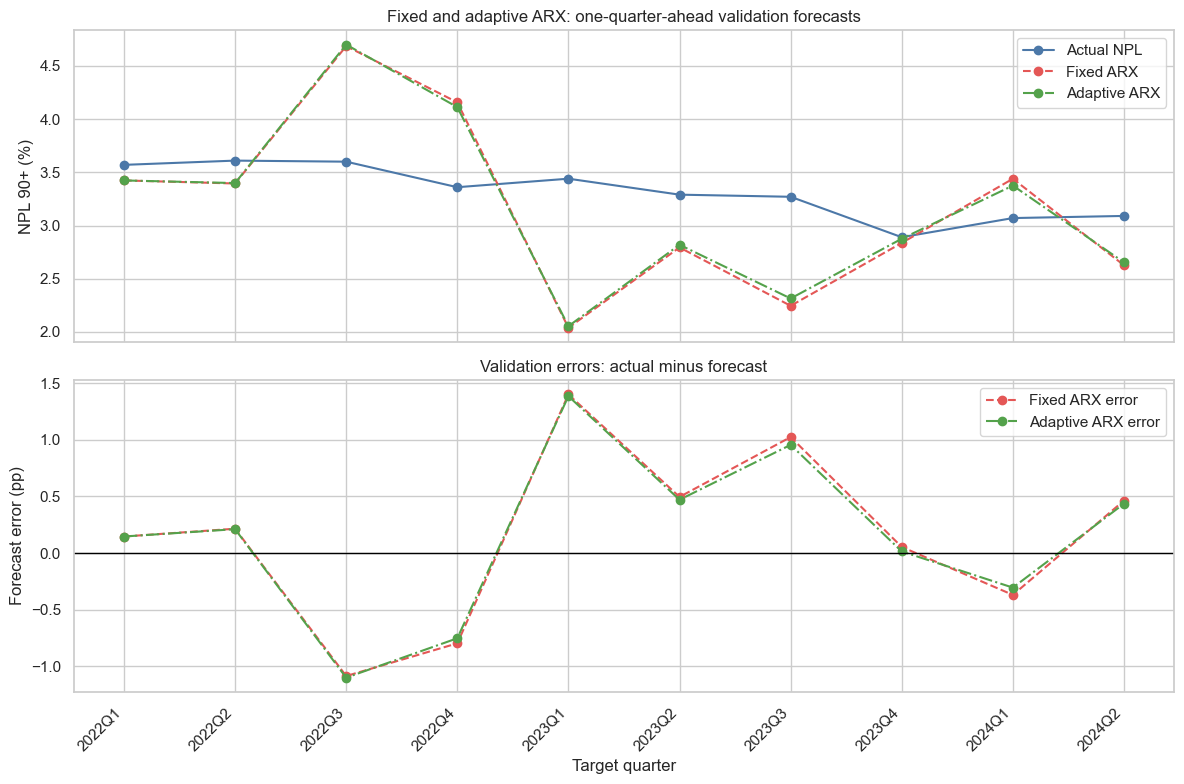

In [17]:
figure, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# keep observations and both forecast paths on a common scale
for column, label, color, linestyle in [
    ("actual_npl", "Actual NPL", "#4C78A8", "-"),
    ("fixed_npl", "Fixed ARX", "#E45756", "--"),
    ("adaptive_npl", "Adaptive ARX", "#54A24B", "-."),
]:
    axes[0].plot(
        quarter_positions,
        validation_forecast_comparison[column],
        color=color,
        linestyle=linestyle,
        marker="o",
        label=label,
    )
axes[0].set(
    title="Fixed and adaptive ARX: one-quarter-ahead validation forecasts",
    ylabel="NPL 90+ (%)",
)
axes[0].legend()

# compare signed errors without hiding the original fixed-model results
for column, label, color, linestyle in [
    ("fixed_error_pp", "Fixed ARX error", "#E45756", "--"),
    ("adaptive_error_pp", "Adaptive ARX error", "#54A24B", "-."),
]:
    axes[1].plot(
        quarter_positions,
        validation_forecast_comparison[column],
        color=color,
        linestyle=linestyle,
        marker="o",
        label=label,
    )
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(
    title="Validation errors: actual minus forecast",
    xlabel="Target quarter",
    ylabel="Forecast error (pp)",
)
axes[1].legend()
axes[1].set_xticks(quarter_positions)
axes[1].set_xticklabels(
    validation_data.index.astype(str), rotation=45, ha="right"
)

figure.tight_layout()
plt.show()
plt.close(figure)

### Validation review

Adaptive refitting reduces MAE from 0.605 to 0.578 pp and RMSE from 0.741 to 0.720 pp, improvements of approximately 4.5% and 2.9%. Sizeable swings remain; expanding-window fits retain all earlier observations and adapt gradually.

The improvement is modest and does not establish a structural-break correction or final-test superiority. The fixed model remains unchanged.

### Save the adaptive results

Save forecasts, estimation dates and sample sizes, coefficient history and comparison metrics in `reports/diagnostics/05_adaptive_validation.json`. Keep the original fixed-model artifact unchanged.

In [18]:
def frame_to_records(frame):
    # preserve full precision while converting period labels to json strings
    records = []
    for row in frame.reset_index().to_dict(orient="records"):
        record = {}
        for key, value in row.items():
            if isinstance(value, pd.Period):
                record[key] = str(value)
            elif isinstance(value, np.generic):
                record[key] = value.item()
            else:
                record[key] = value
        records.append(record)
    return records


adaptive_validation_artifact = {
    "status": "supplementary_adaptive_validation_only",
    "model": ADAPTIVE_MODEL_NAME,
    "fixed_model": MAIN_MODEL_NAME,
    "fixed_protocol_sha256": fixed_protocol_hash,
    "predictors": selected_predictors,
    "transformations": candidate_manifest["transformations"],
    "validation_start": str(VALIDATION_START),
    "validation_end": str(VALIDATION_END),
    "forecast_rules": {
        "horizon_quarters": 1,
        "refit_policy": "expanding-window OLS at each origin through target minus one",
        "initial_estimation_sample": "2011Q2–2021Q4; 43 complete rows",
        "last_validation_estimation_sample": "2011Q2–2024Q1; 52 complete rows",
        "history_update": "add actual previously observed validation outcomes",
        "availability_assumption": "previous-quarter data observed; no release-vintage simulation",
        "lag_selection": "unchanged oil2 + FX4 with NPL-change lags 1–2",
        "strict_pre_2022_parameter_fitting": False,
        "bias_correction": False,
        "prediction_clipping": False,
        "excluded_quarters": [],
    },
    "validation_forecasts": frame_to_records(adaptive_validation_results),
    "coefficient_history": frame_to_records(adaptive_coefficient_history),
    "comparison_metrics": frame_to_records(validation_comparison),
    "error_reductions": frame_to_records(adaptive_improvement),
    "final_testing_performed": False,
    "benchmarks_evaluated": [],
    "stress_scenario_performed": False,
    "final_interpretation_written": False,
}

assert len(adaptive_validation_artifact["validation_forecasts"]) == 10
assert len(adaptive_validation_artifact["coefficient_history"]) == 10
assert all(
    pd.Period(row["fit_end"], freq=QUARTER_FREQUENCY)
    < pd.Period(row["quarter"], freq=QUARTER_FREQUENCY)
    for row in adaptive_validation_artifact["validation_forecasts"]
)
assert hashlib.sha256(
    VALIDATION_PROTOCOL_PATH.read_bytes()
).hexdigest() == fixed_protocol_hash
pd.testing.assert_series_equal(arx_result.params, frozen_parameters, check_exact=True)

# keep the adaptive record separate and protect existing results from silent changes
if ADAPTIVE_VALIDATION_PATH.exists():
    saved_adaptive_artifact = json.loads(
        ADAPTIVE_VALIDATION_PATH.read_text(encoding="utf-8")
    )
    assert saved_adaptive_artifact == adaptive_validation_artifact, (
        "The saved adaptive experiment differs. Review before replacing the artifact."
    )
else:
    ADAPTIVE_VALIDATION_PATH.write_text(
        json.dumps(adaptive_validation_artifact, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
    )

assert json.loads(
    ADAPTIVE_VALIDATION_PATH.read_text(encoding="utf-8")
) == adaptive_validation_artifact
print(f"Saved adaptive validation experiment: {ADAPTIVE_VALIDATION_PATH}")
print("Final testing, AR(2), persistence, scenario and final interpretation remain deferred.")

Saved adaptive validation experiment: ../reports/diagnostics/05_adaptive_validation.json
Final testing, AR(2), persistence, scenario and final interpretation remain deferred.


## Conclusion

Validation is complete for both ARX update policies on the same ten quarters. Adaptive refitting modestly improves MAE and RMSE, but sizeable forecast errors remain. The fixed pre-2022 model is preserved, and the adaptive results are saved separately as a supplementary experiment. Notebook 6, the final notebook, will compare both policies with AR(2) and persistence on the reserved test period, evaluate the four-quarter oil/FX stress scenario and present the final interpretation and limitations. These remaining stages have not yet been performed.